# Лабораторная работа № 2. Атаки уклонения FGSM и PGD на классификаторы дорожных знаков (GTSRB)

**Задачи работы**

1. Реализовать атаки уклонения по методу белого ящика (white-box evasion attacks) против классификаторов на основе глубокого обучения.
2. Получить практические навыки переноса атак уклонения (black-box transfer) против моделей машинного обучения.

**План ноутбука** (нумерация совпадает с заданием)

| Раздел | Что делаем |
|---|---|
| 0 | Окружение, импорты, параметры |
| 1 | Датасет GTSRB: загрузка, предобработка, распределение классов, разбиение train/val/test |
| **Задание 1** | Дообучение предобученных на ImageNet сетей **VGG16** и **ResNet50**, подбор гиперпараметров, Таблица 1, графики loss/accuracy |
| **Задание 2** | Нецелевые атаки **FGSM** и **PGD** (библиотека ART) на первые 1000 тестовых изображений, 10 значений ε, Таблица 2, графики, примеры |
| Дополнительно | Перенос атакующих примеров между моделями (black-box transfer) |
| **Задание 3** | Целевая атака на знак «Стоп» (класс 14) → «Ограничение скорости 30» (класс 1), PGD и FGSM, Таблица 3, примеры |
| Выводы | Итоги по всем заданиям |

Ноутбук рассчитан на запуск «сверху вниз». Он работает и на CPU, и на GPU (Google Colab): устройство выбирается автоматически.

## 0. Окружение

В Google Colab и Kaggle нужно доустановить только библиотеку **Adversarial Robustness Toolbox (ART)**: PyTorch, torchvision,
scikit-learn, pandas и matplotlib там уже есть. Следующая ячейка ставит ART сама, если его нет.

In [1]:
# ART (Adversarial Robustness Toolbox) ставится автоматически, если его ещё нет.
# Внимание: пакет на pip называется adversarial-robustness-toolbox, а импортируется как art.
# Пакет с pip, который называется просто "art", это другая библиотека (ASCII-арт), ставить её не нужно.
import importlib.util, subprocess, sys

def art_installed():
    try:
        return importlib.util.find_spec('art.attacks') is not None
    except ModuleNotFoundError:
        return False

if not art_installed():
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'adversarial-robustness-toolbox'])
    importlib.invalidate_caches()
print('ART установлен:', art_installed())
# Вне Colab/Kaggle также нужны: pip install torch torchvision scikit-learn pandas matplotlib

ART установлен: True


In [2]:
import os, time, copy, random, zipfile, urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from sklearn.model_selection import GroupShuffleSplit

import art
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import FastGradientMethod, ProjectedGradientDescent

# ---------------- параметры эксперимента ----------------
SEED        = 42
IMG_SIZE    = 32      # размер изображений из задания: 32x32
NUM_CLASSES = 43
BATCH_SIZE  = 128
EPOCHS      = 6       # эпох финального обучения каждой модели
HP_SUBSET   = 8000    # сколько обучающих картинок брать для быстрого подбора гиперпараметров
HP_EPOCHS   = 2       # эпох на одну конфигурацию при подборе
RETRAIN     = False   # True = обучать заново, даже если в checkpoints/ уже есть веса

N_ATTACK    = 1000    # «первые 1000 изображений тестового множества»
PGD_ITERS   = 10      # итераций PGD (нецелевая атака)
PGD_ITERS_T = 20      # итераций PGD (целевая атака, задание 3)

DATA_DIR, RES_DIR, IMG_DIR, CKPT_DIR = 'data', 'results', 'images', 'checkpoints'
for d in (DATA_DIR, RES_DIR, IMG_DIR, CKPT_DIR):
    os.makedirs(d, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
set_seed()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cpu':
    torch.set_num_threads(os.cpu_count())

print('torch', torch.__version__, '| ART', art.__version__, '| device:', DEVICE,
      '| CPU threads:', torch.get_num_threads())

torch 2.14.1+cpu | ART 1.20.1 | device: cpu | CPU threads: 4


In [3]:
# Названия 43 классов GTSRB (индекс = ClassId)
CLASS_NAMES = [
    'Огр. 20', 'Огр. 30', 'Огр. 50', 'Огр. 60', 'Огр. 70', 'Огр. 80', 'Конец огр. 80', 'Огр. 100', 'Огр. 120',
    'Обгон запрещён', 'Обгон грузовикам запрещён', 'Пересечение со второстеп.', 'Главная дорога', 'Уступи дорогу',
    'Стоп', 'Движение запрещено', 'Грузовикам запрещено', 'Въезд запрещён', 'Прочие опасности',
    'Опасный поворот налево', 'Опасный поворот направо', 'Двойной поворот', 'Неровная дорога', 'Скользкая дорога',
    'Сужение справа', 'Дорожные работы', 'Светофор', 'Пешеходы', 'Дети', 'Велосипедисты', 'Гололёд',
    'Дикие животные', 'Конец всех ограничений', 'Поворот направо', 'Поворот налево', 'Прямо',
    'Прямо или направо', 'Прямо или налево', 'Объезд справа', 'Объезд слева', 'Круговое движение',
    'Конец запрета обгона', 'Конец запрета обгона груз.',
]
STOP_CLASS, TARGET_CLASS = 14, 1   # «Стоп» и «Ограничение скорости 30»
assert len(CLASS_NAMES) == NUM_CLASSES

## 1. Датасет GTSRB

**German Traffic Sign Recognition Benchmark**: 39 209 обучающих и 12 630 тестовых фотографий дорожных знаков, 43 класса,
всего ≈ 51 800 изображений. Скачиваем три официальных архива с сайта авторов (≈ 365 МБ). Распаковывать их не нужно:
картинки читаются прямо из zip.

Каждую картинку приводим к размеру **32×32** и храним как `uint8` (0…255). Результат кэшируется в `data/gtsrb_32.npz`,
чтобы при повторном запуске не читать 52 тысячи файлов заново.

Важная деталь обучающей части: снимки сгруппированы в **треки** (track), по 30 кадров одного и того же физического знака,
снятых при приближении машины. Номер трека записан в имени файла: `00012_00029.ppm` означает трек 12, кадр 29.
Это понадобится при разбиении на train и validation.

In [4]:
BASE_URL = 'https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/'
ARCHIVES = ['GTSRB_Final_Training_Images.zip', 'GTSRB_Final_Test_Images.zip', 'GTSRB_Final_Test_GT.zip']

for fname in ARCHIVES:
    path = os.path.join(DATA_DIR, fname)
    if os.path.exists(path):
        print(f'{fname}: уже скачан ({os.path.getsize(path)/2**20:.0f} МБ)')
    else:
        print(f'{fname}: скачиваю...')
        urllib.request.urlretrieve(BASE_URL + fname, path)
        print(f'   готово ({os.path.getsize(path)/2**20:.0f} МБ)')

GTSRB_Final_Training_Images.zip: уже скачан (263 МБ)
GTSRB_Final_Test_Images.zip: уже скачан (85 МБ)
GTSRB_Final_Test_GT.zip: уже скачан (0 МБ)


In [5]:
def read_image(zf, name):
    # Читает одну .ppm из zip-архива и приводит её к IMG_SIZE x IMG_SIZE x 3, uint8
    with zf.open(name) as fh:
        img = Image.open(fh).convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.asarray(img, dtype=np.uint8)

def load_train(zip_path):
    # Обучающая часть: в каждой папке класса есть GT-000XX.csv со списком файлов и меток
    X, y, tracks = [], [], []
    with zipfile.ZipFile(zip_path) as zf:
        for csv_name in sorted(n for n in zf.namelist() if n.endswith('.csv')):
            folder = os.path.dirname(csv_name)
            df = pd.read_csv(zf.open(csv_name), sep=';')
            for fname, cid in zip(df['Filename'], df['ClassId']):
                X.append(read_image(zf, f'{folder}/{fname}'))
                y.append(cid)
                tracks.append(cid * 1000 + int(fname.split('_')[0]))   # уникальный id трека
    return np.stack(X), np.array(y, dtype=np.int64), np.array(tracks)

def load_test(img_zip, gt_zip):
    # Тестовая часть: картинки лежат в одной папке, метки в отдельном GT-final_test.csv
    with zipfile.ZipFile(gt_zip) as zf:
        gt = pd.read_csv(zf.open('GT-final_test.csv'), sep=';')
    with zipfile.ZipFile(img_zip) as zf:
        X = np.stack([read_image(zf, 'GTSRB/Final_Test/Images/' + f) for f in gt['Filename']])
    return X, gt['ClassId'].values.astype(np.int64)

CACHE = os.path.join(DATA_DIR, f'gtsrb_{IMG_SIZE}.npz')
if os.path.exists(CACHE):
    d = np.load(CACHE)
    X_all, y_all, tracks_all, X_test, y_test = (d[k] for k in ['X_all', 'y_all', 'tracks_all', 'X_test', 'y_test'])
    print('Загружено из кэша', CACHE)
else:
    t0 = time.time()
    X_all, y_all, tracks_all = load_train(os.path.join(DATA_DIR, ARCHIVES[0]))
    X_test, y_test = load_test(os.path.join(DATA_DIR, ARCHIVES[1]), os.path.join(DATA_DIR, ARCHIVES[2]))
    np.savez_compressed(CACHE, X_all=X_all, y_all=y_all, tracks_all=tracks_all, X_test=X_test, y_test=y_test)
    print(f'Предобработка заняла {time.time() - t0:.0f} c, кэш сохранён в {CACHE}')

print('Обучающая часть:', X_all.shape, '| тест:', X_test.shape, '| всего изображений:', len(X_all) + len(X_test))
print('Треков в обучающей части:', len(np.unique(tracks_all)))
print('Знаков «Стоп» (класс 14) в тесте:', (y_test == STOP_CLASS).sum())

Загружено из кэша data/gtsrb_32.npz
Обучающая часть: (39209, 32, 32, 3) | тест: (12630, 32, 32, 3) | всего изображений: 51839
Треков в обучающей части: 1307
Знаков «Стоп» (класс 14) в тесте: 270


### 1.1. Распределение изображений по классам (аналог рис. 1 задания)

Классы сильно несбалансированы: знаков «Ограничение 50» больше 2000, а «Ограничение 20» всего около 200.
Поэтому accuracy на тесте в основном определяется частыми классами.

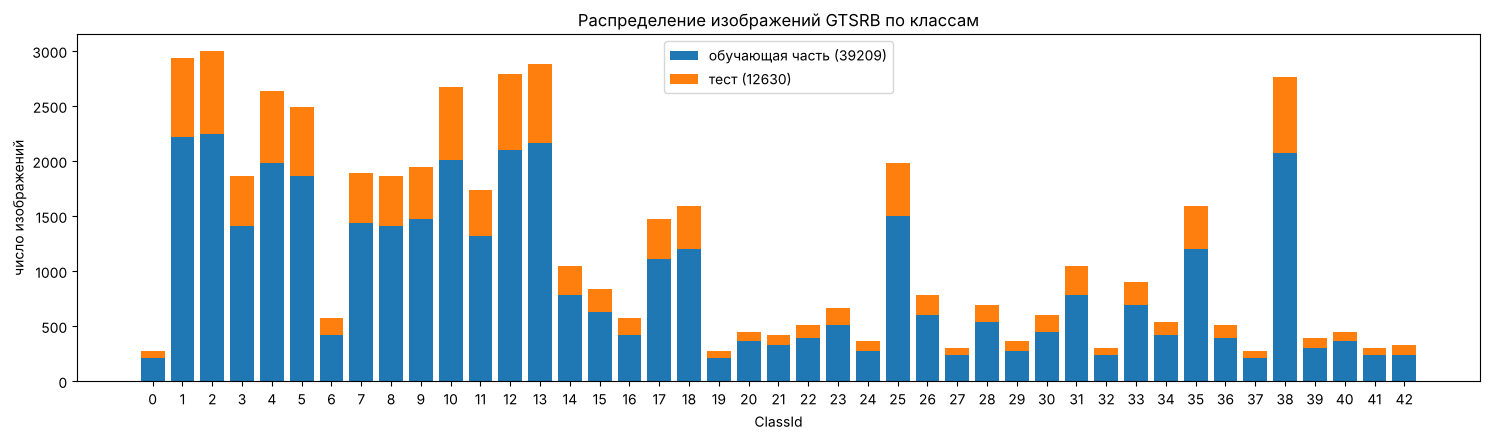

Самый частый класс : 2 Огр. 50 2250
Самый редкий класс : 0 Огр. 20 210


In [6]:
cnt_train = np.bincount(y_all, minlength=NUM_CLASSES)
cnt_test  = np.bincount(y_test, minlength=NUM_CLASSES)

fig, ax = plt.subplots(figsize=(15, 4.5))
ax.bar(np.arange(NUM_CLASSES), cnt_train, label=f'обучающая часть ({len(y_all)})', color='tab:blue')
ax.bar(np.arange(NUM_CLASSES), cnt_test, bottom=cnt_train, label=f'тест ({len(y_test)})', color='tab:orange')
ax.set_xticks(np.arange(NUM_CLASSES))
ax.set_xlabel('ClassId'); ax.set_ylabel('число изображений')
ax.set_title('Распределение изображений GTSRB по классам')
ax.legend(); plt.tight_layout()
plt.savefig(f'{IMG_DIR}/class_distribution.png', dpi=120); plt.show()

print('Самый частый класс :', cnt_train.argmax(), CLASS_NAMES[cnt_train.argmax()], cnt_train.max())
print('Самый редкий класс :', cnt_train.argmin(), CLASS_NAMES[cnt_train.argmin()], cnt_train.min())

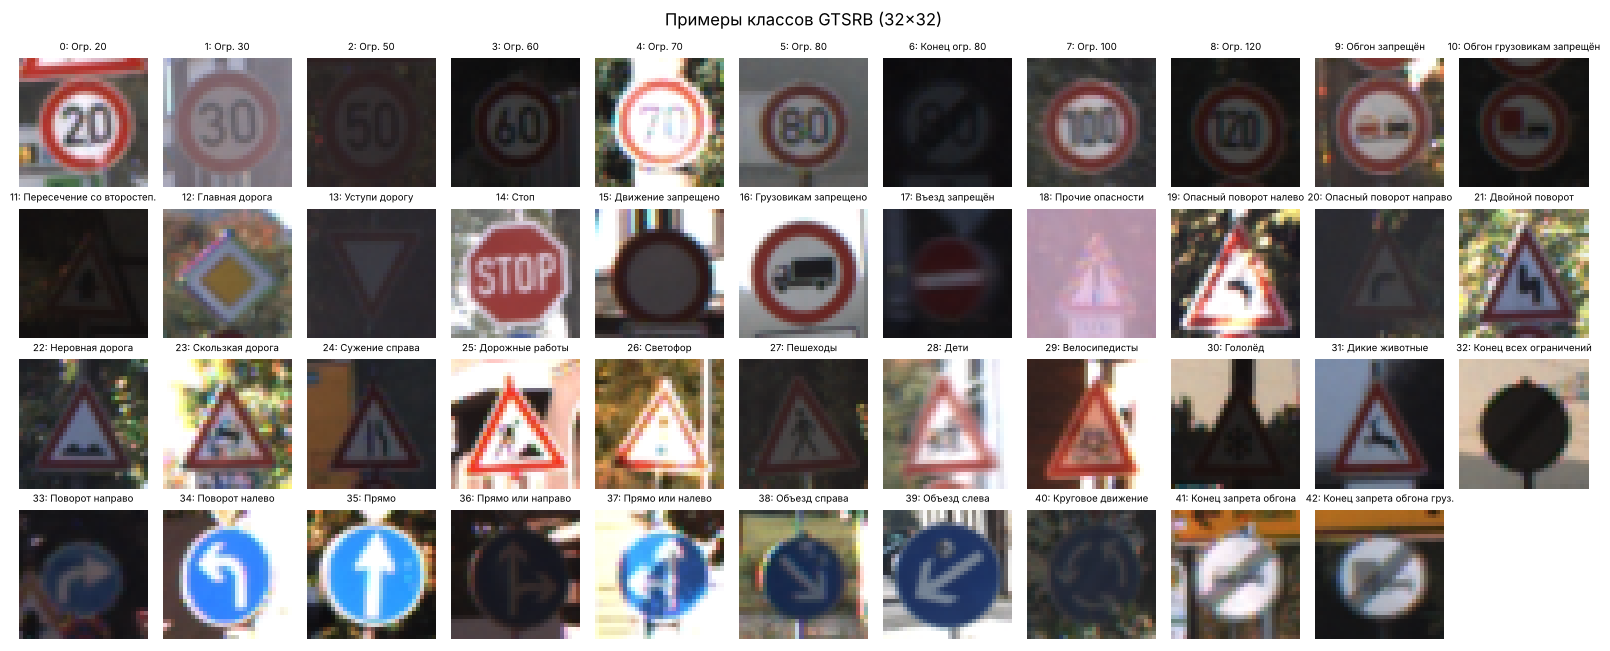

In [7]:
# По одному примеру каждого класса (после уменьшения до 32x32)
fig, axes = plt.subplots(4, 11, figsize=(16, 6.6))
for cid, ax in enumerate(axes.flat):
    ax.axis('off')
    if cid < NUM_CLASSES:
        ax.imshow(X_all[np.where(y_all == cid)[0][15]])
        ax.set_title(f'{cid}: {CLASS_NAMES[cid]}', fontsize=7)
plt.suptitle('Примеры классов GTSRB (32×32)'); plt.tight_layout()
plt.savefig(f'{IMG_DIR}/class_examples.png', dpi=120); plt.show()

### 1.2. Разбиение train / validation / test

* **test** — официальная тестовая часть GTSRB (12 630 изображений). Она не участвует ни в обучении, ни в выборе гиперпараметров.
* **validation** отделяем от обучающей части: 20 % **треков**, а не 20 % случайных картинок.

Почему по трекам: 30 кадров одного трека почти одинаковы. При случайном разбиении «близнецы» одной картинки попадут и в train,
и в validation, и validation-accuracy будет завышена (модель фактически видела эти знаки). `GroupShuffleSplit` следит,
чтобы каждый трек целиком попал в одну из частей.

In [8]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, val_idx = next(gss.split(X_all, y_all, groups=tracks_all))
assert not set(tracks_all[tr_idx]) & set(tracks_all[val_idx])   # ни один трек не попал в обе части

def to_tensor(X):
    # (N, H, W, C) uint8 -> (N, C, H, W) uint8; в float переводим по батчам, чтобы экономить память
    return torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()

X_tr,  y_tr  = to_tensor(X_all[tr_idx]),  torch.from_numpy(y_all[tr_idx])
X_val, y_val = to_tensor(X_all[val_idx]), torch.from_numpy(y_all[val_idx])
X_te,  y_te  = to_tensor(X_test),         torch.from_numpy(y_test)

print(f'train: {len(X_tr)} | validation: {len(X_val)} | test: {len(X_te)}')
print('классов в validation:', len(torch.unique(y_val)))

train: 31349 | validation: 7860 | test: 12630
классов в validation: 39


## Задание 1. Обучение классификаторов VGG16 и ResNet50

### 1.3. Модели

Обе сети берутся из `torchvision.models` с весами, **предобученными на ImageNet** (transfer learning). Сеть с нуля не пишем,
меняем только «голову»:

* **VGG16**: оставляем свёрточную часть `features` (13 conv-слоёв). На входе 32×32 после пяти max-pool получается
  карта 512×1×1. Штатный классификатор VGG рассчитан на 7×7×512 → 4096 → 4096 → 1000 и для нас избыточен (≈120 млн параметров),
  поэтому ставим маленькую голову: `Flatten → Dropout → Linear(512, 256) → ReLU → Dropout → Linear(256, 43)`.
* **ResNet50**: заменяем последний слой `fc` (2048 → 1000) на `Linear(2048, 43)`.

Нормализация ImageNet (`mean`, `std`) встроена **внутрь модели** первым слоем `Normalize`. Поэтому модель принимает
картинку в диапазоне **[0, 1]**, и ε атак измеряется прямо в долях яркости пикселя: ε = 8/255 значит «каждый пиксель
изменился не больше чем на 8 уровней яркости из 255». Если нормализацию сделать снаружи, ε пришлось бы пересчитывать.

In [9]:
class Normalize(nn.Module):
    # Нормализация ImageNet внутри модели: вход в [0, 1], выход (x - mean) / std
    def __init__(self, mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)):
        super().__init__()
        self.register_buffer('mean', torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor(std).view(1, 3, 1, 1))
    def forward(self, x):
        return (x - self.mean) / self.std

def build_vgg16(pretrained=True):
    base = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1 if pretrained else None)
    head = nn.Sequential(nn.Flatten(), nn.Dropout(0.5), nn.Linear(512, 256), nn.ReLU(inplace=True),
                         nn.Dropout(0.5), nn.Linear(256, NUM_CLASSES))
    return nn.Sequential(Normalize(), base.features, head)

def build_resnet50(pretrained=True):
    base = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
    base.fc = nn.Linear(base.fc.in_features, NUM_CLASSES)
    return nn.Sequential(Normalize(), base)

BUILDERS = {'VGG16': build_vgg16, 'ResNet50': build_resnet50}

for name, build in BUILDERS.items():
    m = build()
    n_params = sum(p.numel() for p in m.parameters())
    out = m.eval()(torch.rand(2, 3, IMG_SIZE, IMG_SIZE))
    print(f'{name:9s}: {n_params/1e6:5.1f} млн параметров, выход на батч 2x3x32x32 -> {tuple(out.shape)}')
del m

VGG16    :  14.9 млн параметров, выход на батч 2x3x32x32 -> (2, 43)


ResNet50 :  23.6 млн параметров, выход на батч 2x3x32x32 -> (2, 43)


### 1.4. Обучение и оценка

* **Аугментация** (только на обучении): случайный сдвиг до ±3 пикселей и случайное изменение яркости и контраста ±20 %.
  **Горизонтальное отражение не используем**: зеркальный «Поворот налево» превращается в «Поворот направо», то есть
  в картинку другого класса.
* **Оптимизатор и lr** выбираются на шаге подбора гиперпараметров (п. 1.5); скорость обучения плавно уменьшается
  по косинусу (`CosineAnnealingLR`).
* После каждой эпохи считаем loss и accuracy на **validation** и **test**: задание требует графики для обоих.
  Лучшую эпоху выбираем **только по validation**. Выбор по тесту был бы «подглядыванием», и оценка на тесте стала бы
  нечестной.
* Train-loss и train-accuracy на графиках — средние по эпохе на аугментированных батчах с включённым Dropout.
  Для Таблицы 1 accuracy на обучающей выборке пересчитывается отдельно, на чистых картинках в режиме `eval()`.

In [10]:
def batches(X, y, bs, shuffle):
    # Генератор батчей: uint8 -> float в [0, 1]
    idx = torch.randperm(len(X)) if shuffle else torch.arange(len(X))
    for s in range(0, len(X), bs):
        b = idx[s:s + bs]
        yield X[b].float().div_(255), y[b]

def augment(x, max_shift=3):
    # Случайный сдвиг (pad + crop) и яркость/контраст, для каждой картинки свои параметры
    n, _, h, w = x.shape
    xp = F.pad(x, (max_shift,) * 4, mode='replicate')
    dx = torch.randint(0, 2 * max_shift + 1, (n,)).tolist()
    dy = torch.randint(0, 2 * max_shift + 1, (n,)).tolist()
    x = torch.stack([xp[k, :, dy[k]:dy[k] + h, dx[k]:dx[k] + w] for k in range(n)])
    contrast   = torch.empty(n, 1, 1, 1).uniform_(0.8, 1.2)
    brightness = torch.empty(n, 1, 1, 1).uniform_(0.8, 1.2)
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    return (((x - mean) * contrast + mean) * brightness).clamp_(0, 1)

@torch.no_grad()
def evaluate(model, X, y, bs=512):
    # Средний loss и accuracy на выборке (eval-режим, без аугментации)
    model.eval()
    loss_sum, correct = 0.0, 0
    for xb, yb in batches(X, y, bs, shuffle=False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        out = model(xb)
        loss_sum += F.cross_entropy(out, yb, reduction='sum').item()
        correct  += (out.argmax(1) == yb).sum().item()
    return loss_sum / len(X), correct / len(X)

def make_optimizer(model, opt, lr):
    if opt == 'adam':
        return torch.optim.Adam(model.parameters(), lr=lr)
    if opt == 'sgd':
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4, nesterov=True)
    raise ValueError(opt)

def train_model(model, X_train, y_train, epochs, opt='adam', lr=1e-3, bs=BATCH_SIZE,
                X_valid=None, y_valid=None, X_tst=None, y_tst=None, verbose=True):
    model.to(DEVICE)
    optimizer = make_optimizer(model, opt, lr)
    steps = epochs * ((len(X_train) + bs - 1) // bs)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps)
    history, best_acc, best_state = [], -1.0, None
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time()
        loss_sum, correct, n = 0.0, 0, 0
        for xb, yb in batches(X_train, y_train, bs, shuffle=True):
            xb, yb = augment(xb).to(DEVICE), yb.to(DEVICE)
            out  = model(xb)
            loss = F.cross_entropy(out, yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step(); scheduler.step()
            loss_sum += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
        rec = {'epoch': ep, 'train_loss': loss_sum / n, 'train_acc': correct / n}
        if X_valid is not None:
            rec['val_loss'], rec['val_acc'] = evaluate(model, X_valid, y_valid)
        if X_tst is not None:
            rec['test_loss'], rec['test_acc'] = evaluate(model, X_tst, y_tst)
        rec['time_s'] = time.time() - t0
        history.append(rec)
        if verbose:
            print('  ' + ' | '.join(f'{k}={v:.4f}' if isinstance(v, float) else f'{k}={v}' for k, v in rec.items()))
        if X_valid is not None and rec['val_acc'] > best_acc:      # запоминаем лучшую эпоху по validation
            best_acc, best_state = rec['val_acc'], copy.deepcopy(model.state_dict())
    if best_state is not None:
        model.load_state_dict(best_state)
    return pd.DataFrame(history)

### 1.5. Подбор гиперпараметров

Задание требует найти лучшие гиперпараметры. Полный перебор с обучением до конца на CPU занял бы много часов,
поэтому используем стандартный компромисс:

* каждая конфигурация учится **2 эпохи на случайном подмножестве из 8000** обучающих картинок;
* качество сравниваем по **validation-accuracy** (тест в подборе не участвует);
* перебираем оптимизатор и скорость обучения (learning rate). Это гиперпараметры, сильнее всего влияющие на fine-tuning.

Лучшая конфигурация затем используется для полного обучения.

In [11]:
HP_GRID = [
    {'opt': 'adam', 'lr': 1e-3},
    {'opt': 'adam', 'lr': 3e-4},
    {'opt': 'adam', 'lr': 1e-4},
    {'opt': 'sgd',  'lr': 1e-2},
]

hp_file = f'{RES_DIR}/hparam_search.csv'
if os.path.exists(hp_file) and not RETRAIN:
    hp_results = pd.read_csv(hp_file)
    print('Результаты подбора загружены из', hp_file)
else:
    g = torch.Generator().manual_seed(SEED)
    sub = torch.randperm(len(X_tr), generator=g)[:HP_SUBSET]
    rows = []
    for name, build in BUILDERS.items():
        for cfg in HP_GRID:
            set_seed()
            print(f'{name} {cfg}')
            t0 = time.time()
            h = train_model(build(), X_tr[sub], y_tr[sub], HP_EPOCHS, **cfg,
                            X_valid=X_val, y_valid=y_val, verbose=False)
            rows.append({'model': name, **cfg, 'val_acc': h['val_acc'].max(),
                         'val_loss': h['val_loss'].min(), 'time_s': time.time() - t0})
            print(f"   -> val_acc = {rows[-1]['val_acc']:.4f} ({rows[-1]['time_s']:.0f} c)")
    hp_results = pd.DataFrame(rows)
    hp_results.to_csv(hp_file, index=False)

BEST_HP = {}
for name in BUILDERS:
    r = hp_results[hp_results.model == name].sort_values('val_acc', ascending=False).iloc[0]
    BEST_HP[name] = {'opt': r['opt'], 'lr': float(r['lr'])}
    print(f'Лучшие гиперпараметры {name}: {BEST_HP[name]} (val_acc = {r.val_acc:.4f})')

hp_results.pivot_table(index=['opt', 'lr'], columns='model', values='val_acc').style.format('{:.2%}')

VGG16 {'opt': 'adam', 'lr': 0.001}


   -> val_acc = 0.3734 (172 c)
VGG16 {'opt': 'adam', 'lr': 0.0003}


   -> val_acc = 0.4978 (170 c)
VGG16 {'opt': 'adam', 'lr': 0.0001}


   -> val_acc = 0.4426 (169 c)
VGG16 {'opt': 'sgd', 'lr': 0.01}


   -> val_acc = 0.5050 (171 c)
ResNet50 {'opt': 'adam', 'lr': 0.001}


   -> val_acc = 0.8420 (113 c)
ResNet50 {'opt': 'adam', 'lr': 0.0003}


   -> val_acc = 0.4721 (118 c)
ResNet50 {'opt': 'adam', 'lr': 0.0001}


   -> val_acc = 0.2048 (115 c)
ResNet50 {'opt': 'sgd', 'lr': 0.01}


   -> val_acc = 0.5366 (115 c)
Лучшие гиперпараметры VGG16: {'opt': 'sgd', 'lr': 0.01} (val_acc = 0.5050)
Лучшие гиперпараметры ResNet50: {'opt': 'adam', 'lr': 0.001} (val_acc = 0.8420)


### 1.6. Финальное обучение VGG16 и ResNet50

Обучаем каждую модель на всей обучающей части (train без validation) с лучшими гиперпараметрами.
Веса и история обучения сохраняются в `checkpoints/`. При `RETRAIN = False` и наличии сохранённых файлов обучение
пропускается и всё загружается с диска. Это удобно в Colab, если сессия оборвалась после обучения.

In [12]:
trained, histories = {}, {}
for name, build in BUILDERS.items():
    ckpt, hist_file = f'{CKPT_DIR}/{name}.pt', f'{RES_DIR}/history_{name}.csv'
    model = build(pretrained=not (os.path.exists(ckpt) and not RETRAIN))
    if os.path.exists(ckpt) and os.path.exists(hist_file) and not RETRAIN:
        model.load_state_dict(torch.load(ckpt, map_location='cpu'))
        histories[name] = pd.read_csv(hist_file)
        print(f'{name}: веса загружены из {ckpt}')
    else:
        set_seed()
        print(f'=== {name}: обучение {EPOCHS} эпох, {BEST_HP[name]} ===')
        t0 = time.time()
        histories[name] = train_model(model, X_tr, y_tr, EPOCHS, **BEST_HP[name],
                                      X_valid=X_val, y_valid=y_val, X_tst=X_te, y_tst=y_te)
        print(f'{name}: обучение заняло {(time.time() - t0)/60:.1f} мин')
        torch.save(model.state_dict(), ckpt)
        histories[name].to_csv(hist_file, index=False)
    trained[name] = model.to(DEVICE).eval()

=== VGG16: обучение 6 эпох, {'opt': 'sgd', 'lr': 0.01} ===


  epoch=1 | train_loss=1.3702 | train_acc=0.5721 | val_loss=0.4167 | val_acc=0.8747 | test_loss=0.3550 | test_acc=0.8859 | time_s=337.3690


  epoch=2 | train_loss=0.2272 | train_acc=0.9275 | val_loss=0.2285 | val_acc=0.9489 | test_loss=0.1919 | test_acc=0.9473 | time_s=347.3792


  epoch=3 | train_loss=0.0683 | train_acc=0.9796 | val_loss=0.1232 | val_acc=0.9687 | test_loss=0.1948 | test_acc=0.9583 | time_s=323.7880


  epoch=4 | train_loss=0.0273 | train_acc=0.9922 | val_loss=0.1215 | val_acc=0.9771 | test_loss=0.1231 | test_acc=0.9739 | time_s=315.4078


...

  epoch=2 | train_loss=0.0940 | train_acc=0.9727 | val_loss=0.1493 | val_acc=0.9609 | test_loss=0.2611 | test_acc=0.9355 | time_s=207.4476


  epoch=3 | train_loss=0.0421 | train_acc=0.9877 | val_loss=0.1979 | val_acc=0.9508 | test_loss=0.2549 | test_acc=0.9368 | time_s=209.2559


  epoch=4 | train_loss=0.0199 | train_acc=0.9939 | val_loss=0.1520 | val_acc=0.9645 | test_loss=0.2007 | test_acc=0.9537 | time_s=218.8711


  epoch=5 | train_loss=0.0063 | train_acc=0.9981 | val_loss=0.1315 | val_acc=0.9700 | test_loss=0.1921 | test_acc=0.9592 | time_s=213.1956


  epoch=6 | train_loss=0.0049 | train_acc=0.9988 | val_loss=0.1342 | val_acc=0.9684 | test_loss=0.1918 | test_acc=0.9603 | time_s=201.8435
ResNet50: обучение заняло 21.1 мин


### 1.7. Графики функции потерь и accuracy (аналог рис. 2)

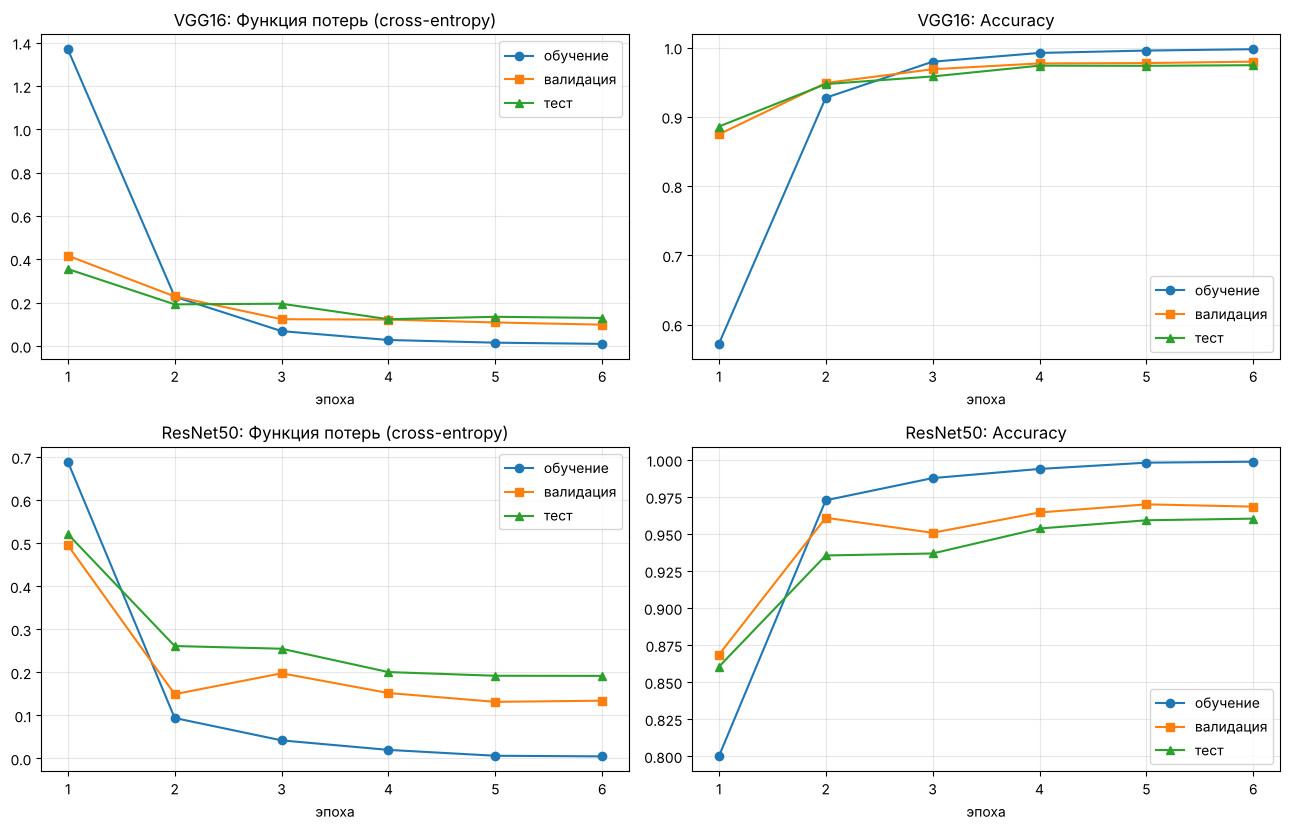

In [13]:
fig, axes = plt.subplots(len(trained), 2, figsize=(13, 4.2 * len(trained)))
for row, (name, h) in zip(axes, histories.items()):
    for ax, metric, title in [(row[0], 'loss', 'Функция потерь (cross-entropy)'), (row[1], 'acc', 'Accuracy')]:
        for part, label, style in [('train', 'обучение', 'o-'), ('val', 'валидация', 's-'), ('test', 'тест', '^-')]:
            ax.plot(h['epoch'], h[f'{part}_{metric}'], style, label=label)
        ax.set_title(f'{name}: {title}'); ax.set_xlabel('эпоха'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(f'{IMG_DIR}/training_curves.png', dpi=120); plt.show()

### 1.8. Таблица 1. Accuracy моделей на обучающей, валидационной и тестовой выборках

In [14]:
rows = []
for name, model in trained.items():
    res = {'Модель': name}
    for part, (X, y) in {'Обучение': (X_tr, y_tr), 'Валидация': (X_val, y_val), 'Тест': (X_te, y_te)}.items():
        loss, acc = evaluate(model, X, y)
        res[part], res[f'{part} (loss)'] = acc, loss
    rows.append(res)
table1 = pd.DataFrame(rows).set_index('Модель')
table1.to_csv(f'{RES_DIR}/table1_accuracy.csv')

display(table1[['Обучение', 'Валидация', 'Тест']].style.format('{:.2%}').set_caption('Таблица 1. Accuracy'))
display(table1[['Обучение (loss)', 'Валидация (loss)', 'Тест (loss)']].style.format('{:.4f}').set_caption('Loss'))

,Обучение,Валидация,Тест
Модель,,,
VGG16,99.94%,97.96%,97.45%
ResNet50,99.98%,97.00%,95.92%


,Обучение (loss),Валидация (loss),Тест (loss)
Модель,,,
VGG16,0.0022,0.0981,0.1291
ResNet50,0.0007,0.1315,0.1921


## Задание 2. Нецелевые атаки FGSM и PGD (белый ящик)

**Белый ящик** (white-box): атакующий знает архитектуру и веса модели и может считать градиенты.
**Нецелевая** (untargeted) атака: нужно, чтобы модель ошиблась, а в какой класс она уйдёт, неважно.

* **FGSM** (Fast Gradient Sign Method, Goodfellow et al., 2014) делает один шаг:
  $x_{adv} = \mathrm{clip}_{[0,1]}\big(x + \varepsilon\cdot\mathrm{sign}(\nabla_x L(f(x), y))\big)$.
* **PGD** (Projected Gradient Descent, Madry et al., 2017) повторяет маленькие шаги FGSM размера $\alpha$ и после каждого
  шага проецирует результат обратно в $\varepsilon$-окрестность исходной картинки (по норме $L_\infty$) и в [0, 1]:
  $x^{t+1} = \Pi_{\|x'-x\|_\infty\le\varepsilon}\big(x^t + \alpha\cdot\mathrm{sign}(\nabla_x L(f(x^t), y))\big)$.
  Здесь `max_iter = 10`, $\alpha = \varepsilon/4$ (суммарный путь 2.5ε, стандартное правило Madry et al.).

Атаки берём из **Adversarial Robustness Toolbox (ART)**. Для этого модель оборачивается в `PyTorchClassifier`:
он умеет делать предсказания и считать градиент функции потерь по входу. `clip_values=(0, 1)` сообщает атакам
допустимый диапазон пикселей.

**Важно: функция потерь для атак — `StableCrossEntropy`, а не обычная `nn.CrossEntropyLoss`.** Хорошо обученная сеть
очень уверена в ответах: логит правильного класса больше остальных на 20–70 единиц. Тогда softmax в float32 даёт
вероятность правильного класса ровно `1.0`, а градиент кросс-энтропии получается порядка $e^{-40}pprox 10^{-18}$ и меньше.
При обратном проходе через сеть в float32 такие числа теряют точность, и знак градиента для части пикселей становится
случайным. Атака получает плохое направление и выглядит слабее, чем есть на самом деле. Это **маскировка градиента**
(gradient masking), ложное ощущение стойкости.

`StableCrossEntropy` делает две вещи:
1. считает кросс-энтропию точно, без округления $p_y$ до 1: $CE = \log\big(1 + \sum_{j\ne y} e^{z_j - z_y}\big)$ в float64;
2. возвращает $\sum_i \log CE_i$. Логарифм монотонен, поэтому **знак** градиента по каждой картинке тот же, что у $CE_i$,
   а FGSM и PGD с нормой $L_\infty$ используют только знак. Значит, сами атаки по определению не меняются, но градиент
   теперь порядка единицы, и точность float32 больше не мешает.

Ячейка 2.0 ниже показывает разницу на практике.

In [15]:
class StableCrossEntropy(nn.CrossEntropyLoss):
    # Функция потерь для атак: сумма log(CE) по картинкам, CE посчитана без потери точности.
    # Знак градиента по каждой картинке совпадает со знаком градиента обычной CE, поэтому FGSM/PGD не меняются,
    # но градиент имеет порядок 1, а не 1e-20 (иначе у очень уверенной модели он «тонет» в ошибках округления).
    # Наследуемся от CrossEntropyLoss, чтобы ART по-прежнему передавал метки как номера классов.
    def forward(self, logits, target):
        z = logits.double()
        z_y = z.gather(1, target[:, None])                          # логит правильного (или целевого) класса
        others = z.scatter(1, target[:, None], float('-inf'))       # остальные логиты
        a = torch.logsumexp(others - z_y, dim=1)                    # CE = softplus(a) = log(1 + sum exp(z_j - z_y))
        log_ce = torch.where(a < -30, a, torch.log(F.softplus(a.clamp_min(-30))))   # при a < -30 log(CE) = a
        return log_ce.sum()

def make_art_classifier(model, loss=None):
    model.eval()
    return PyTorchClassifier(
        model=model,
        loss=loss if loss is not None else StableCrossEntropy(),
        input_shape=(3, IMG_SIZE, IMG_SIZE),
        nb_classes=NUM_CLASSES,
        clip_values=(0.0, 1.0),
        device_type='gpu' if DEVICE.type == 'cuda' else 'cpu',
    )

art_clf = {name: make_art_classifier(m) for name, m in trained.items()}

# Фабрика атак ART: FGSM или PGD с нормой L_inf
def make_attack(kind, clf, eps, targeted=False, iters=PGD_ITERS):
    if kind == 'FGSM':
        return FastGradientMethod(clf, norm=np.inf, eps=eps, targeted=targeted, batch_size=256)
    if kind == 'PGD':
        return ProjectedGradientDescent(clf, norm=np.inf, eps=eps, eps_step=2.5 * eps / iters, max_iter=iters,
                                        targeted=targeted, num_random_init=0, batch_size=128, verbose=False)
    raise ValueError(kind)

# Первые 1000 изображений тестового множества
x_att = X_test[:N_ATTACK].transpose(0, 3, 1, 2).astype(np.float32) / 255.0   # (1000, 3, 32, 32), [0, 1]
y_att = y_test[:N_ATTACK]
y_att_onehot = np.eye(NUM_CLASSES, dtype=np.float32)[y_att]

def predict(clf, x, bs=256):
    return clf.predict(x, batch_size=bs).argmax(1)

for name, clf in art_clf.items():
    print(f'{name}: accuracy на первых {N_ATTACK} тестовых изображениях = {(predict(clf, x_att) == y_att).mean():.2%}')

VGG16: accuracy на первых 1000 тестовых изображениях = 97.70%


ResNet50: accuracy на первых 1000 тестовых изображениях = 96.70%


### 2.0. Почему обычная кросс-энтропия «маскирует» градиент

Сравним одни и те же атаки с обычной `nn.CrossEntropyLoss` и со `StableCrossEntropy`: FGSM при ε = 10/255 на 1000 картинках
и PGD при ε = 80/255 на первых 300 (при таком ε белая атака должна ломать почти всё).
Заодно посмотрим, насколько модели уверены: **отрыв** — разница между самым большим и вторым по величине логитом.

In [16]:
rows = []
for name, model in trained.items():
    logits = art_clf[name].predict(x_att)
    top2 = np.sort(logits, axis=1)[:, -2:]
    p_max = torch.softmax(torch.from_numpy(logits), dim=1).max(1).values      # softmax в float32
    plain = make_art_classifier(model, loss=nn.CrossEntropyLoss())
    row = {'Модель': name,
           'Медианный отрыв логитов': np.median(top2[:, 1] - top2[:, 0]),
           'Доля картинок с p = 1.0 ровно (float32)': (p_max == 1.0).float().mean().item()}
    for label, clf in [('обычная CE', plain), ('StableCE', art_clf[name])]:
        x_adv = FastGradientMethod(clf, norm=np.inf, eps=10 / 255, batch_size=256).generate(x=x_att, y=y_att_onehot)
        row[f'FGSM ε=10/255, {label}'] = (predict(art_clf[name], x_adv) == y_att).mean()
    for label, clf in [('обычная CE', plain), ('StableCE', art_clf[name])]:
        x_adv = make_attack('PGD', clf, 80 / 255).generate(x=x_att[:300], y=y_att_onehot[:300])
        row[f'PGD ε=80/255, {label}'] = (predict(art_clf[name], x_adv) == y_att[:300]).mean()
    rows.append(row)
masking = pd.DataFrame(rows).set_index('Модель')
masking.to_csv(f'{RES_DIR}/gradient_masking_check.csv')
masking.style.format(lambda v: f'{v:.1f}' if v > 1 else f'{v:.1%}')

,Медианный отрыв логитов,Доля картинок с p = 1.0 ровно (float32),"FGSM ε=10/255, обычная CE","FGSM ε=10/255, StableCE","PGD ε=80/255, обычная CE","PGD ε=80/255, StableCE"
Модель,,,,,,
VGG16,21.3,66.6%,60.3%,23.0%,20.0%,0.0%
ResNet50,11.9,4.7%,26.6%,26.2%,0.0%,0.0%


### 2.1. Запуск атак для всех ε

ε = [1, 2, 3, 4, 5, 8, 10, 20, 50, 80] / 255. Для каждой модели, атаки и ε генерируем 1000 атакующих примеров
и считаем accuracy на них (по **истинным** меткам).

Попутно (раздел «Дополнительно» ниже) те же атакующие примеры подаём **второй** модели. Это перенос атаки
по схеме чёрного ящика: пример построен по градиентам VGG16, а атакуем ResNet50, и наоборот.

Для иллюстрации FGSM запоминаем атакующие версии нескольких картинок при ε = [1, 5, 10, 50, 80] / 255.

In [17]:
EPS_LIST  = [1, 2, 3, 4, 5, 8, 10, 20, 50, 80]     # в единицах 1/255
EPS_SHOW  = [1, 5, 10, 50, 80]
SHOW_IDX  = [0, 1, 4]                              # какие картинки из первых 1000 показать

untargeted_file = f'{RES_DIR}/untargeted_attacks.csv'
fgsm_examples = {name: {} for name in art_clf}
rows = []
for name, clf in art_clf.items():
    other = [n for n in art_clf if n != name][0]
    rows.append({'model': name, 'attack': 'clean', 'eps_255': 0,
                 'accuracy': (predict(clf, x_att) == y_att).mean(),
                 'transfer_to': other, 'transfer_accuracy': (predict(art_clf[other], x_att) == y_att).mean(),
                 'time_s': 0.0})
    for kind in ['FGSM', 'PGD']:
        for e in EPS_LIST:
            t0 = time.time()
            x_adv = make_attack(kind, clf, e / 255).generate(x=x_att, y=y_att_onehot)
            dt = time.time() - t0
            acc = (predict(clf, x_adv) == y_att).mean()
            tr_acc = (predict(art_clf[other], x_adv) == y_att).mean()
            linf = np.abs(x_adv - x_att).max() * 255
            rows.append({'model': name, 'attack': kind, 'eps_255': e, 'accuracy': acc,
                         'transfer_to': other, 'transfer_accuracy': tr_acc, 'time_s': dt})
            print(f'{name:9s} {kind:4s} eps={e:2d}/255: acc={acc:6.2%} | перенос на {other}: {tr_acc:6.2%} '
                  f'| max|δ|={linf:4.1f}/255 | {dt:5.1f} c')
            if kind == 'FGSM' and e in EPS_SHOW:
                fgsm_examples[name][e] = x_adv[SHOW_IDX]

untargeted = pd.DataFrame(rows)
untargeted.to_csv(untargeted_file, index=False)

VGG16     FGSM eps= 1/255: acc=84.40% | перенос на ResNet50: 94.30% | max|δ|= 1.0/255 |   7.5 c


VGG16     FGSM eps= 2/255: acc=68.40% | перенос на ResNet50: 90.20% | max|δ|= 2.0/255 |   7.8 c


VGG16     FGSM eps= 3/255: acc=57.40% | перенос на ResNet50: 85.80% | max|δ|= 3.0/255 |   7.6 c


VGG16     FGSM eps= 4/255: acc=46.50% | перенос на ResNet50: 81.30% | max|δ|= 4.0/255 |   8.4 c


VGG16     FGSM eps= 5/255: acc=39.40% | перенос на ResNet50: 76.30% | max|δ|= 5.0/255 |   7.3 c


...

ResNet50  PGD  eps= 8/255: acc= 3.60% | перенос на VGG16: 74.60% | max|δ|= 8.0/255 |  51.1 c


ResNet50  PGD  eps=10/255: acc= 1.60% | перенос на VGG16: 66.80% | max|δ|=10.0/255 |  51.2 c


ResNet50  PGD  eps=20/255: acc= 0.10% | перенос на VGG16: 41.90% | max|δ|=20.0/255 |  53.0 c


ResNet50  PGD  eps=50/255: acc= 0.00% | перенос на VGG16: 19.20% | max|δ|=50.0/255 |  52.2 c


ResNet50  PGD  eps=80/255: acc= 0.00% | перенос на VGG16:  7.30% | max|δ|=80.0/255 |  52.0 c


### 2.2. Таблица 2. Accuracy на исходных и атакующих изображениях

In [18]:
def acc_at(model, attack, e):
    sel = untargeted[(untargeted.model == model) & (untargeted.attack == attack) & (untargeted.eps_255 == e)]
    return sel['accuracy'].iloc[0]

rows = []
for name in art_clf:
    for kind in ['FGSM', 'PGD']:
        rows.append({'Модель': f'{name} - {kind}',
                     'Исходные изображения': acc_at(name, 'clean', 0),
                     'Adversarial ε=1/255':  acc_at(name, kind, 1),
                     'Adversarial ε=5/255':  acc_at(name, kind, 5),
                     'Adversarial ε=10/255': acc_at(name, kind, 10)})
table2 = pd.DataFrame(rows).set_index('Модель')
table2.to_csv(f'{RES_DIR}/table2_untargeted.csv')
display(table2.style.format('{:.2%}').set_caption('Таблица 2'))

# Полная таблица по всем ε
full = untargeted[untargeted.attack != 'clean'].pivot_table(index=['model', 'attack'], columns='eps_255', values='accuracy')
full.columns = [f'{c}/255' for c in full.columns]
display(full.style.format('{:.1%}').set_caption('Accuracy для всех ε'))

ok = (table2['Adversarial ε=10/255'] < 0.6).all()
print('Требование задания «accuracy < 60% при ε=10/255» выполнено для всех моделей и атак:', ok)

,Исходные изображения,Adversarial ε=1/255,Adversarial ε=5/255,Adversarial ε=10/255
Модель,,,,
VGG16 - FGSM,97.70%,84.40%,39.40%,23.00%
VGG16 - PGD,97.70%,76.40%,11.70%,0.50%
ResNet50 - FGSM,96.70%,77.30%,39.80%,26.20%
ResNet50 - PGD,96.70%,65.70%,9.60%,1.60%


Требование задания «accuracy < 60% при ε=10/255» выполнено для всех моделей и атак: True


### 2.3. Графики зависимости accuracy от ε (аналог рис. 3)

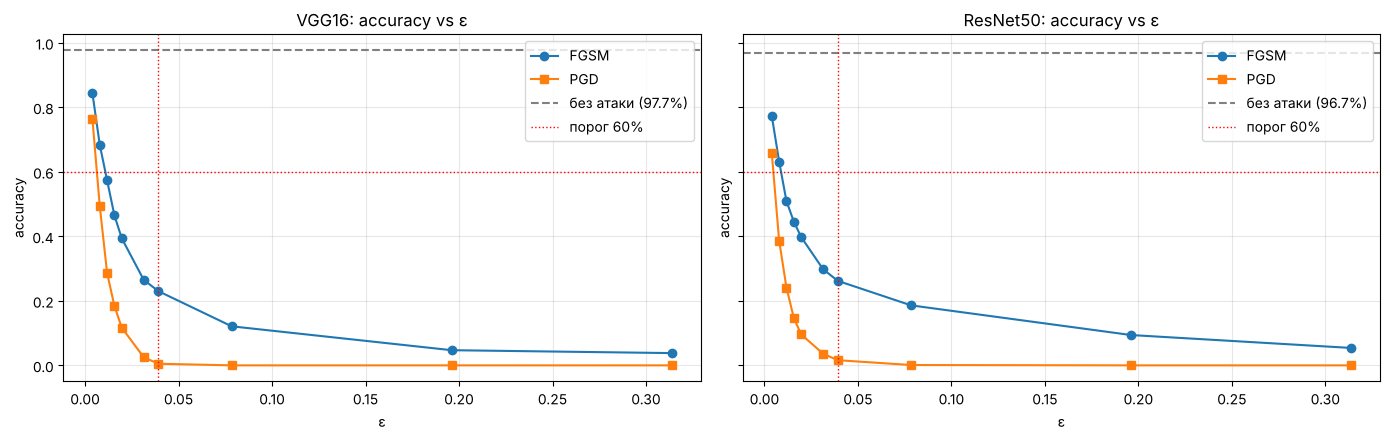

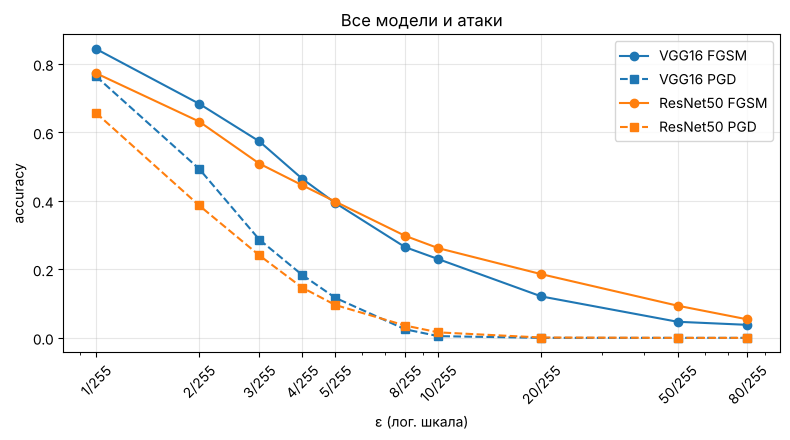

In [19]:
fig, axes = plt.subplots(1, len(art_clf), figsize=(14, 4.5), sharey=True)
for ax, name in zip(axes, art_clf):
    clean = acc_at(name, 'clean', 0)
    for kind, style in [('FGSM', 'o-'), ('PGD', 's-')]:
        sel = untargeted[(untargeted.model == name) & (untargeted.attack == kind)]
        ax.plot(sel.eps_255 / 255, sel.accuracy, style, label=kind)
    ax.axhline(clean, color='gray', ls='--', label=f'без атаки ({clean:.1%})')
    ax.axhline(0.6, color='red', ls=':', lw=1, label='порог 60%')
    ax.axvline(10 / 255, color='red', ls=':', lw=1)
    ax.set_title(f'{name}: accuracy vs ε'); ax.set_xlabel('ε'); ax.set_ylabel('accuracy')
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(f'{IMG_DIR}/accuracy_vs_eps.png', dpi=120); plt.show()

# То же в логарифмическом масштабе по ε: так видна область малых ε
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, color in zip(art_clf, ['tab:blue', 'tab:orange']):
    for kind, style in [('FGSM', 'o-'), ('PGD', 's--')]:
        sel = untargeted[(untargeted.model == name) & (untargeted.attack == kind)]
        ax.plot(sel.eps_255, sel.accuracy, style, color=color, label=f'{name} {kind}')
ax.set_xscale('log'); ax.set_xticks(EPS_LIST); ax.set_xticklabels([f'{e}/255' for e in EPS_LIST], rotation=45)
ax.set_xlabel('ε (лог. шкала)'); ax.set_ylabel('accuracy'); ax.grid(alpha=.3); ax.legend()
ax.set_title('Все модели и атаки')
plt.tight_layout(); plt.savefig(f'{IMG_DIR}/accuracy_vs_eps_log.png', dpi=120); plt.show()

### 2.4. Примеры атакующих изображений FGSM (аналог рис. 4)

Слева исходное изображение, правее атакующие версии при разных ε. Над каждой картинкой подписан класс,
предсказанный моделью (зелёный цвет означает верное предсказание, красный — ошибку).

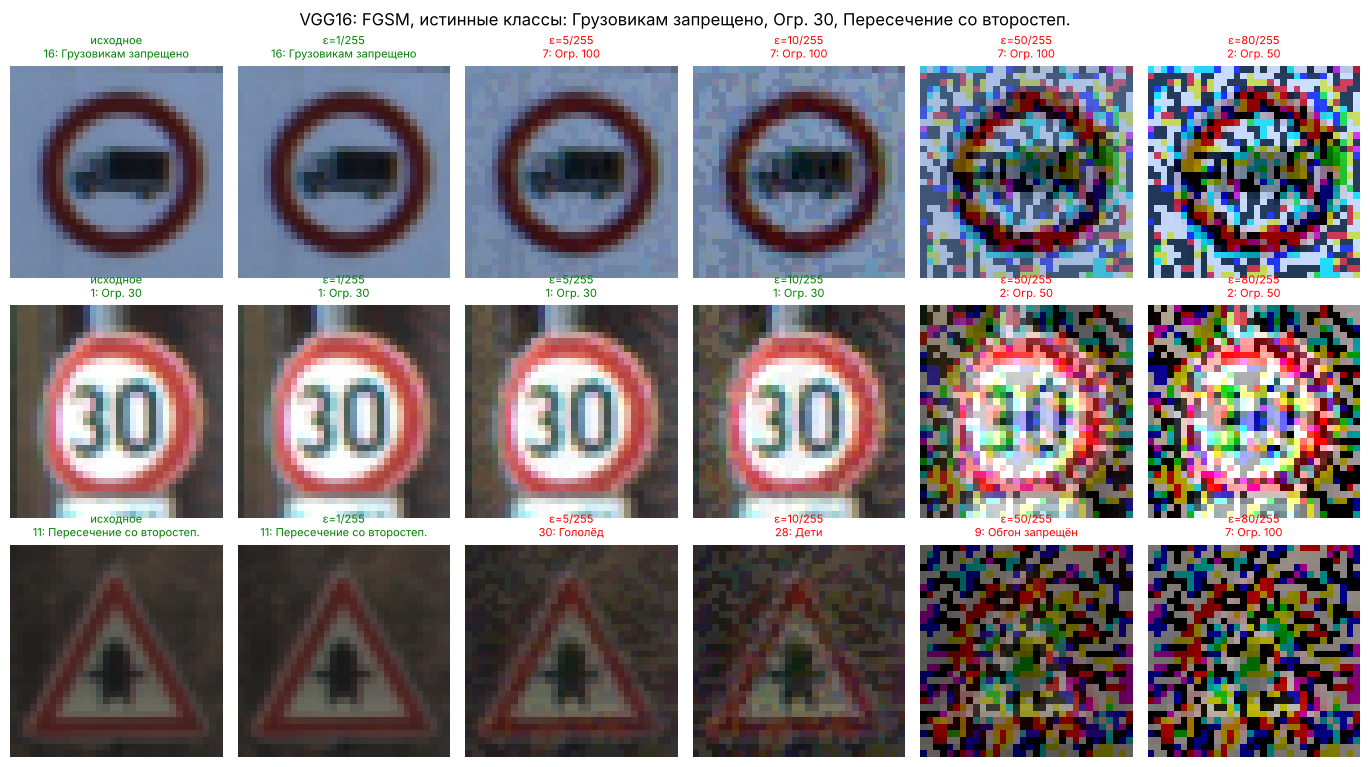

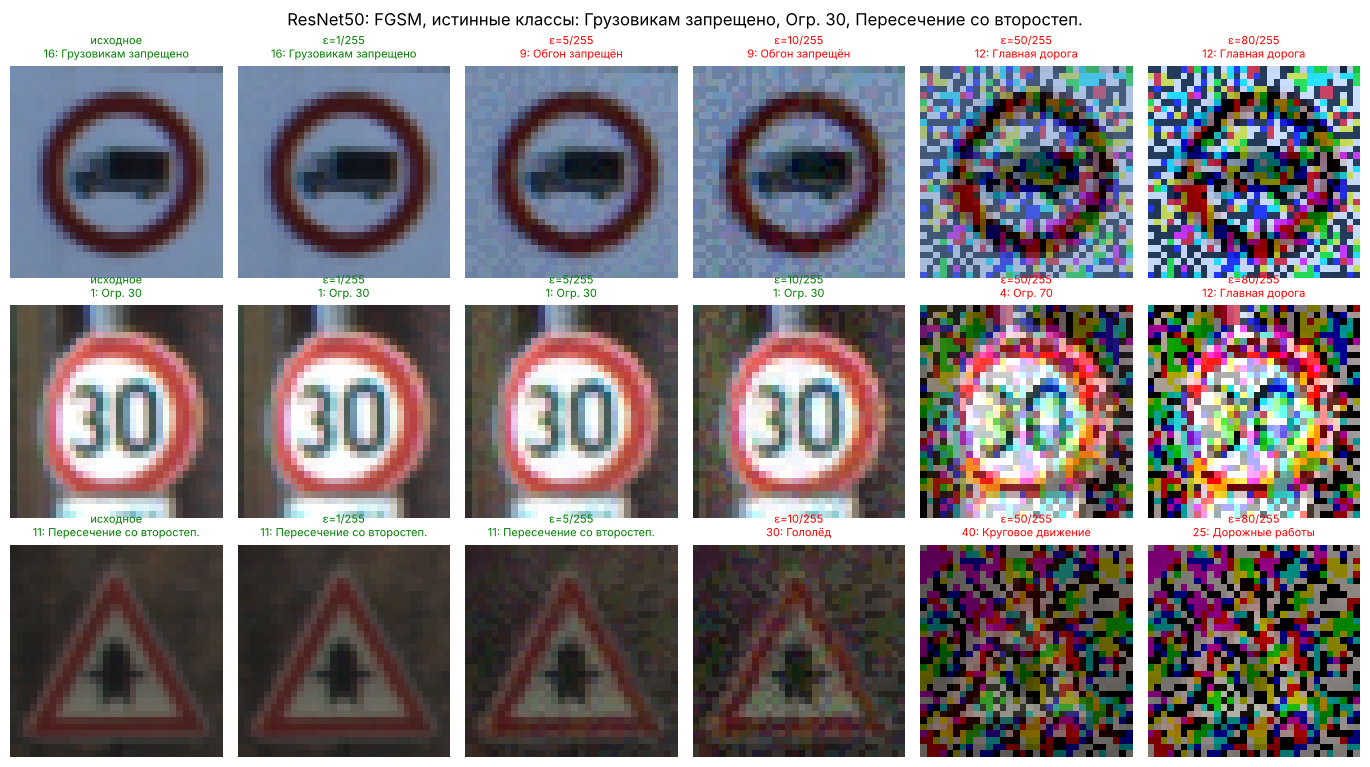

In [20]:
def show_fgsm_examples(name):
    clf = art_clf[name]
    n = len(SHOW_IDX)
    fig, axes = plt.subplots(n, len(EPS_SHOW) + 1, figsize=(2.3 * (len(EPS_SHOW) + 1), 2.6 * n))
    for r, i in enumerate(SHOW_IDX):
        imgs = [x_att[i]] + [fgsm_examples[name][e][r] for e in EPS_SHOW]
        titles = ['исходное'] + [f'ε={e}/255' for e in EPS_SHOW]
        preds = predict(clf, np.stack(imgs))
        for c, (img, t, p) in enumerate(zip(imgs, titles, preds)):
            ax = axes[r, c]; ax.imshow(img.transpose(1, 2, 0)); ax.axis('off')
            ax.set_title(f'{t}\n{p}: {CLASS_NAMES[p]}', fontsize=8, color='green' if p == y_att[i] else 'red')
    plt.suptitle(f'{name}: FGSM, истинные классы: ' + ', '.join(CLASS_NAMES[y_att[i]] for i in SHOW_IDX))
    plt.tight_layout(); plt.savefig(f'{IMG_DIR}/fgsm_examples_{name}.png', dpi=120); plt.show()

for name in art_clf:
    show_fgsm_examples(name)

### Дополнительно. Перенос атак (black-box transfer)

Вторая задача работы — навык переноса атак. Атакующий не знает весов модели-жертвы (чёрный ящик), поэтому строит
примеры на своей **суррогатной** модели и подаёт их жертве. Ниже accuracy модели-жертвы на примерах, построенных по
градиентам другой модели (те же 1000 изображений).

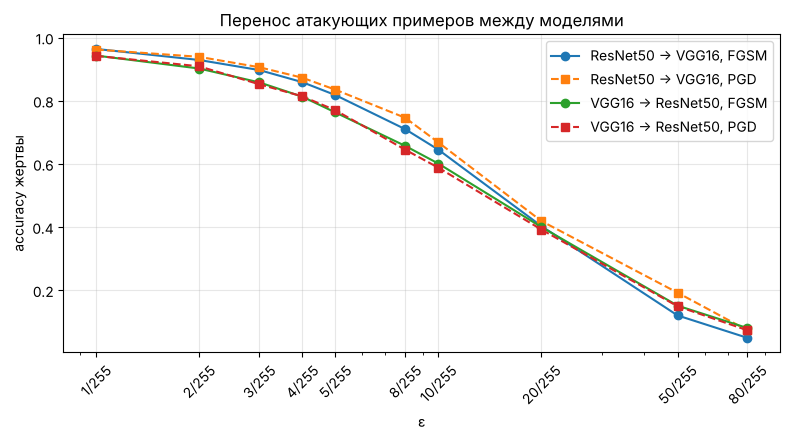

In [21]:
tr = untargeted[untargeted.attack != 'clean'].copy()
tr['пара'] = tr['model'] + ' → ' + tr['transfer_to']
transfer = tr.pivot_table(index=['пара', 'attack'], columns='eps_255', values='transfer_accuracy')
transfer.columns = [f'{c}/255' for c in transfer.columns]
transfer.to_csv(f'{RES_DIR}/transfer_attacks.csv')
display(transfer.style.format('{:.1%}').set_caption('Accuracy жертвы на перенесённых примерах'))

fig, ax = plt.subplots(figsize=(8, 4.5))
for (src, kind), g in tr.groupby(['model', 'attack']):
    ax.plot(g.eps_255, g.transfer_accuracy, 'o-' if kind == 'FGSM' else 's--', label=f'{src} → {g.transfer_to.iloc[0]}, {kind}')
ax.set_xscale('log'); ax.set_xticks(EPS_LIST); ax.set_xticklabels([f'{e}/255' for e in EPS_LIST], rotation=45)
ax.set_xlabel('ε'); ax.set_ylabel('accuracy жертвы'); ax.grid(alpha=.3); ax.legend()
ax.set_title('Перенос атакующих примеров между моделями')
plt.tight_layout(); plt.savefig(f'{IMG_DIR}/transfer.png', dpi=120); plt.show()

## Задание 3. Целевая атака: «Стоп» → «Ограничение скорости 30»

**Целевая** (targeted) атака требует не просто ошибки, а **конкретного** ответа: модель должна принять знак «Стоп»
(класс 14) за «Ограничение скорости 30» (класс 1). Градиентный шаг теперь делается так, чтобы **уменьшить**
функцию потерь относительно целевой метки:
$x_{adv} = x - \alpha\cdot\mathrm{sign}(\nabla_x L(f(x), y_{target}))$. В ART это включается флагом `targeted=True`,
а в `generate` передаются целевые, а не истинные метки.

Берём все 270 тестовых изображений знака «Стоп». Для каждого ε считаем:
* **Stop sign images**: долю картинок, которые модель всё ещё классифицирует как «Стоп» (accuracy по истинной метке);
* **Speed Limit 30 sign images**: долю картинок, классифицированных как «Огр. 30» (успешность целевой атаки).

Шаг 1: PGD (20 итераций, шаг 2.5ε/20). Шаг 2: то же самое для FGSM.

In [22]:
EPS_T = [1, 3, 5, 10, 20, 50, 80]
stop_idx = np.where(y_test == STOP_CLASS)[0]
x_stop = X_test[stop_idx].transpose(0, 3, 1, 2).astype(np.float32) / 255.0
y_target = np.eye(NUM_CLASSES, dtype=np.float32)[np.full(len(x_stop), TARGET_CLASS)]
print('Изображений знака «Стоп» в тесте:', len(x_stop))

EX_STOP = [0, 40, 80, 120, 160]          # 5 примеров для рисунка
EPS_EX  = [5, 10, 20]                    # при каких ε показывать примеры
stop_examples = {}
rows = []
for name, clf in art_clf.items():
    p = predict(clf, x_stop)
    rows.append({'model': name, 'attack': 'clean', 'eps_255': 0,
                 'stop_rate': (p == STOP_CLASS).mean(), 'target_rate': (p == TARGET_CLASS).mean(), 'time_s': 0.0})
    for kind in ['PGD', 'FGSM']:
        for e in EPS_T:
            t0 = time.time()
            atk = make_attack(kind, clf, e / 255, targeted=True, iters=PGD_ITERS_T)
            x_adv = atk.generate(x=x_stop, y=y_target)
            dt = time.time() - t0
            p = predict(clf, x_adv)
            rows.append({'model': name, 'attack': kind, 'eps_255': e, 'stop_rate': (p == STOP_CLASS).mean(),
                         'target_rate': (p == TARGET_CLASS).mean(), 'time_s': dt})
            print(f'{name:9s} {kind:4s} eps={e:2d}/255: «Стоп» {rows[-1]["stop_rate"]:6.2%} | '
                  f'«Огр. 30» {rows[-1]["target_rate"]:6.2%} | {dt:5.1f} c')
            if e in EPS_EX:
                stop_examples[(name, kind, e)] = x_adv[EX_STOP]
targeted = pd.DataFrame(rows)
targeted.to_csv(f'{RES_DIR}/targeted_attacks.csv', index=False)

Изображений знака «Стоп» в тесте: 270


VGG16     PGD  eps= 1/255: «Стоп» 89.26% | «Огр. 30» 10.37% |  42.3 c


VGG16     PGD  eps= 3/255: «Стоп» 32.59% | «Огр. 30» 62.59% |  40.6 c


VGG16     PGD  eps= 5/255: «Стоп»  1.85% | «Огр. 30» 96.67% |  43.2 c


VGG16     PGD  eps=10/255: «Стоп»  0.00% | «Огр. 30» 100.00% |  44.4 c


...

ResNet50  FGSM eps= 5/255: «Стоп» 37.78% | «Огр. 30» 17.41% |   1.3 c


ResNet50  FGSM eps=10/255: «Стоп»  9.63% | «Огр. 30» 18.89% |   1.3 c


ResNet50  FGSM eps=20/255: «Стоп»  2.96% | «Огр. 30» 17.78% |   1.3 c


ResNet50  FGSM eps=50/255: «Стоп»  0.74% | «Огр. 30» 11.48% |   1.2 c


ResNet50  FGSM eps=80/255: «Стоп»  0.00% | «Огр. 30» 10.00% |   1.2 c


### 3.1. Таблица 3. Доля изображений, классифицированных как «Стоп» и как «Ограничение скорости 30»

Колонки PGD — то, что требует Таблица 3 задания. Колонки FGSM добавлены для шага 2 (сравнение методов).

In [23]:
def table3_for(name):
    t = targeted[(targeted.model == name) & (targeted.attack != 'clean')]
    pgd, fgsm = t[t.attack == 'PGD'].set_index('eps_255'), t[t.attack == 'FGSM'].set_index('eps_255')
    tab = pd.DataFrame({
        'PGD attack – Stop sign images':           pgd['stop_rate'],
        'PGD attack – Speed Limit 30 sign images': pgd['target_rate'],
        'FGSM attack – Stop sign images':          fgsm['stop_rate'],
        'FGSM attack – Speed Limit 30 sign images': fgsm['target_rate'],
    })
    tab.index = [f'ε={e}/255' for e in tab.index]; tab.index.name = 'Искажение'
    return tab

for name in art_clf:
    clean = targeted[(targeted.model == name) & (targeted.attack == 'clean')].iloc[0]
    print(f'{name}: без атаки «Стоп» = {clean.stop_rate:.2%}, «Огр. 30» = {clean.target_rate:.2%}')
    t3 = table3_for(name)
    t3.to_csv(f'{RES_DIR}/table3_targeted_{name}.csv')
    display(t3.style.format('{:.2%}').set_caption(f'Таблица 3. {name}'))

VGG16: без атаки «Стоп» = 100.00%, «Огр. 30» = 0.00%


,PGD attack – Stop sign images,PGD attack – Speed Limit 30 sign images,FGSM attack – Stop sign images,FGSM attack – Speed Limit 30 sign images
Искажение,,,,
ε=1/255,89.26%,10.37%,91.85%,4.81%
ε=3/255,32.59%,62.59%,61.11%,12.96%
ε=5/255,1.85%,96.67%,36.30%,13.33%
ε=10/255,0.00%,100.00%,9.63%,17.41%
ε=20/255,0.00%,100.00%,5.56%,7.04%
ε=50/255,0.00%,100.00%,0.00%,0.00%
ε=80/255,0.00%,100.00%,0.00%,0.00%


ResNet50: без атаки «Стоп» = 100.00%, «Огр. 30» = 0.00%


,PGD attack – Stop sign images,PGD attack – Speed Limit 30 sign images,FGSM attack – Stop sign images,FGSM attack – Speed Limit 30 sign images
Искажение,,,,
ε=1/255,91.85%,5.19%,94.07%,1.85%
ε=3/255,34.81%,47.41%,64.81%,11.48%
ε=5/255,12.22%,75.19%,37.78%,17.41%
ε=10/255,4.07%,93.33%,9.63%,18.89%
ε=20/255,0.00%,99.26%,2.96%,17.78%
ε=50/255,0.00%,100.00%,0.74%,11.48%
ε=80/255,0.00%,100.00%,0.00%,10.00%


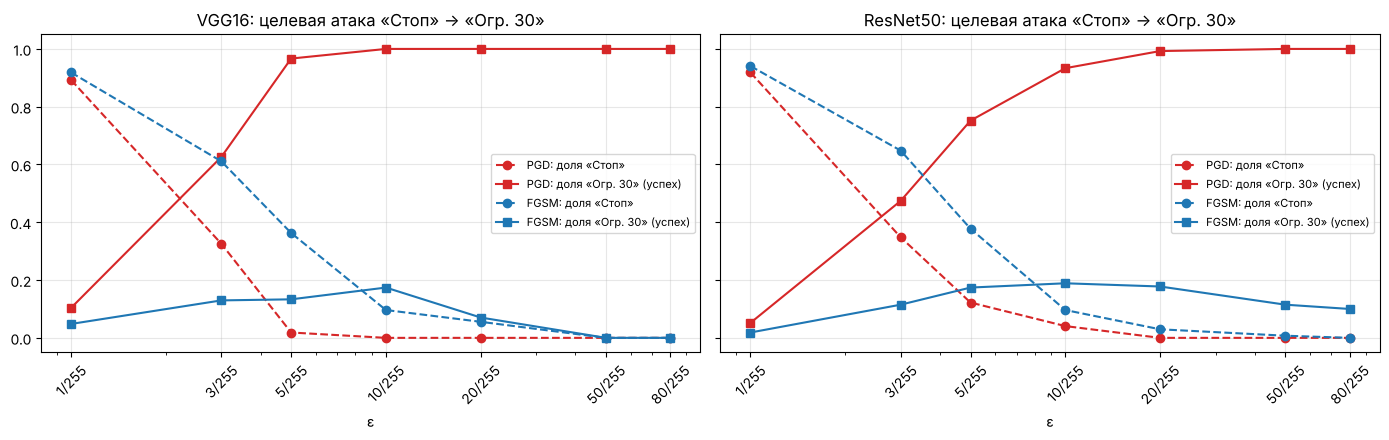

In [24]:
fig, axes = plt.subplots(1, len(art_clf), figsize=(14, 4.5), sharey=True)
for ax, name in zip(axes, art_clf):
    for kind, color in [('PGD', 'tab:red'), ('FGSM', 'tab:blue')]:
        sel = targeted[(targeted.model == name) & (targeted.attack == kind)]
        ax.plot(sel.eps_255, sel.stop_rate,   'o--', color=color, label=f'{kind}: доля «Стоп»')
        ax.plot(sel.eps_255, sel.target_rate, 's-',  color=color, label=f'{kind}: доля «Огр. 30» (успех)')
    ax.set_xscale('log'); ax.set_xticks(EPS_T); ax.set_xticklabels([f'{e}/255' for e in EPS_T], rotation=45)
    ax.set_title(f'{name}: целевая атака «Стоп» → «Огр. 30»'); ax.set_xlabel('ε'); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{IMG_DIR}/targeted_vs_eps.png', dpi=120); plt.show()

### 3.2. Примеры исходных и атакующих изображений знака «Стоп» (аналог рис. 5)

Пять знаков «Стоп» и их атакующие версии (PGD и FGSM при ε = 5/255, 10/255 и 20/255). В подписи указан класс, предсказанный моделью.

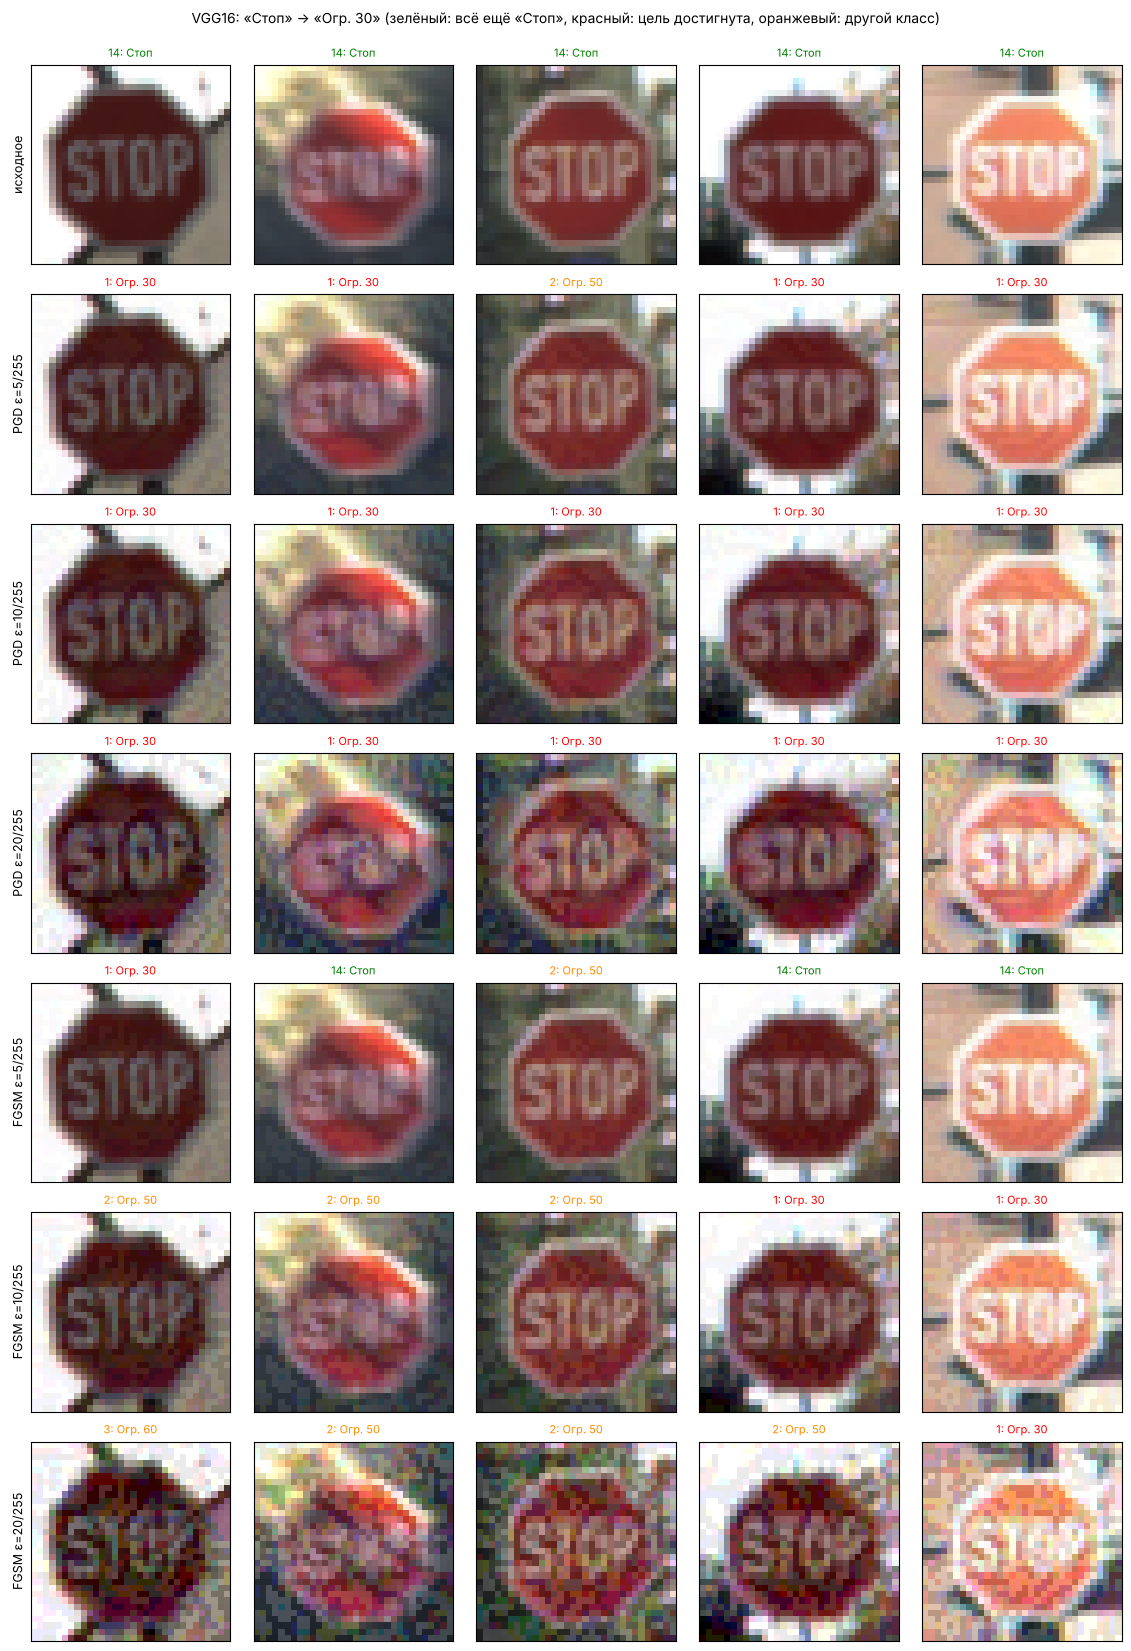

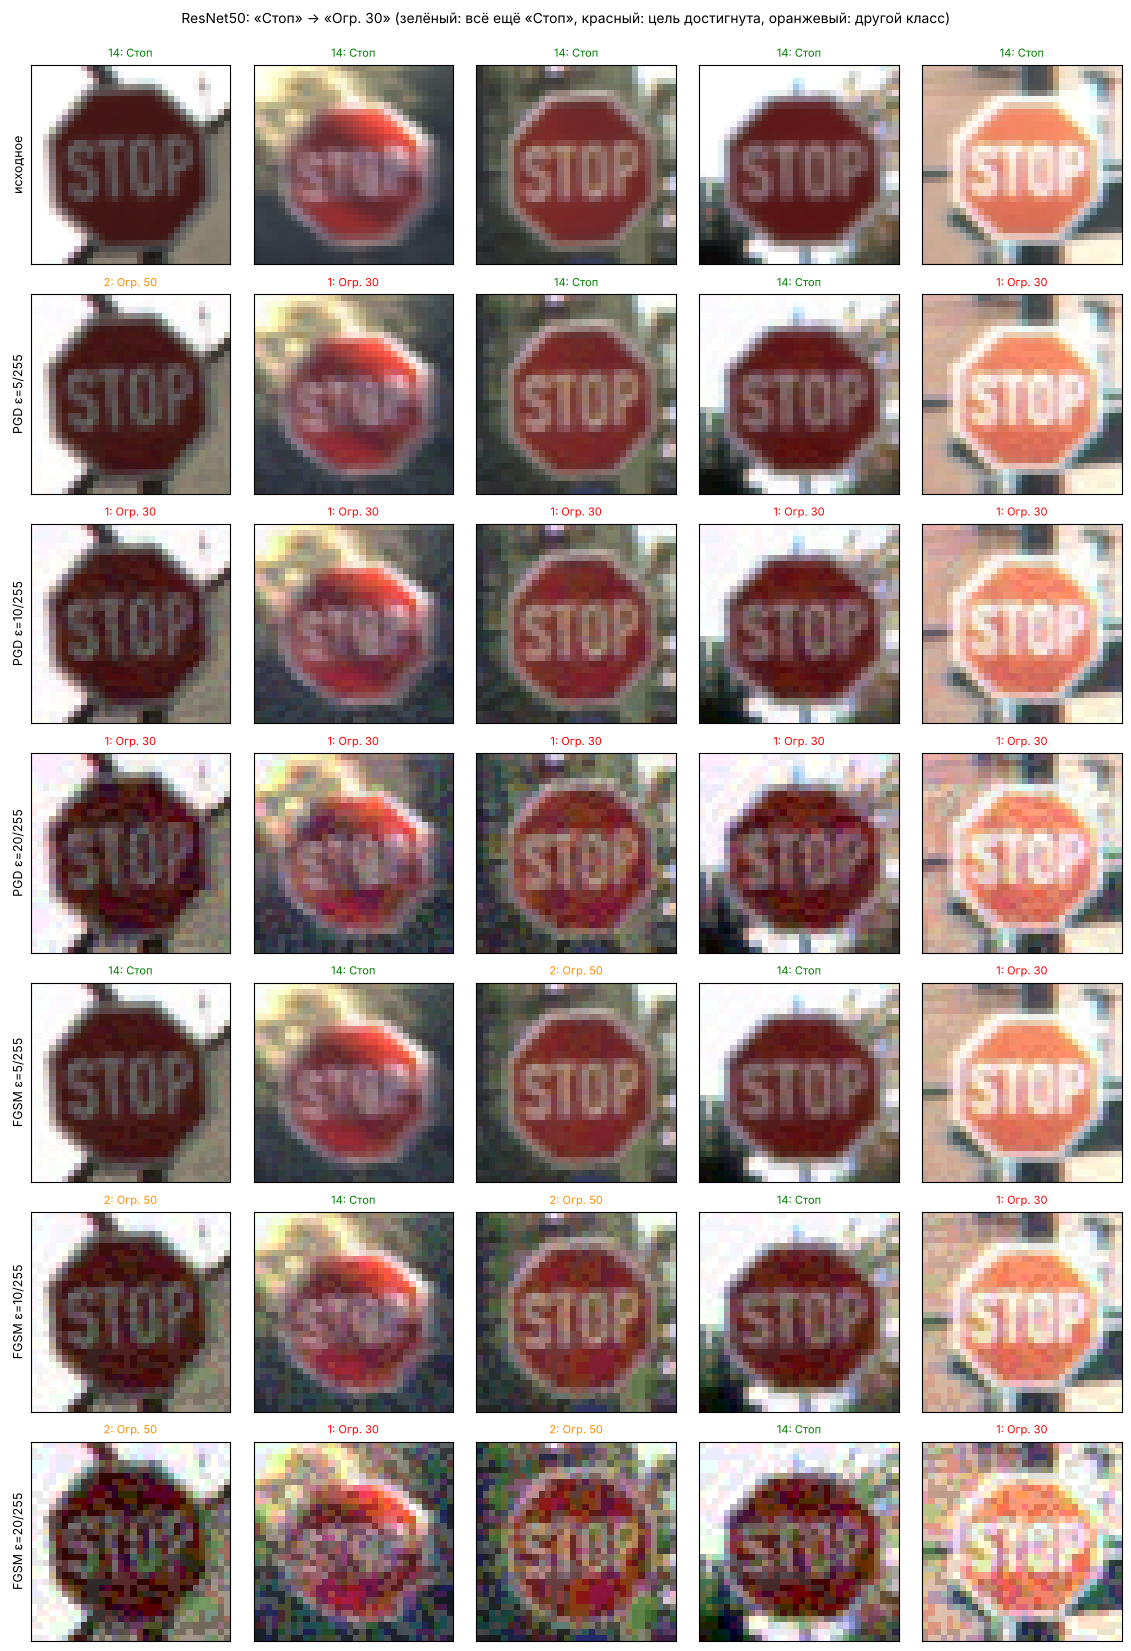

In [25]:
def show_stop_examples(name):
    clf = art_clf[name]
    variants = [('исходное', x_stop[EX_STOP])] + [(f'{k} ε={e}/255', stop_examples[(name, k, e)])
                                                  for k in ['PGD', 'FGSM'] for e in EPS_EX]
    fig, axes = plt.subplots(len(variants), len(EX_STOP), figsize=(2.3 * len(EX_STOP), 2.4 * len(variants)))
    for r, (label, imgs) in enumerate(variants):
        preds = predict(clf, imgs)
        for c in range(len(EX_STOP)):
            ax = axes[r, c]; ax.imshow(imgs[c].transpose(1, 2, 0)); ax.set_xticks([]); ax.set_yticks([])
            color = 'green' if preds[c] == STOP_CLASS else ('red' if preds[c] == TARGET_CLASS else 'darkorange')
            ax.set_title(f'{preds[c]}: {CLASS_NAMES[preds[c]]}', fontsize=8, color=color)
            if c == 0: ax.set_ylabel(label, fontsize=9)
    plt.suptitle(f'{name}: «Стоп» → «Огр. 30» (зелёный: всё ещё «Стоп», красный: цель достигнута, оранжевый: другой класс)',
                 fontsize=10)
    plt.tight_layout(rect=(0, 0, 1, 0.985)); plt.savefig(f'{IMG_DIR}/stop_examples_{name}.png', dpi=120); plt.show()

for name in art_clf:
    show_stop_examples(name)

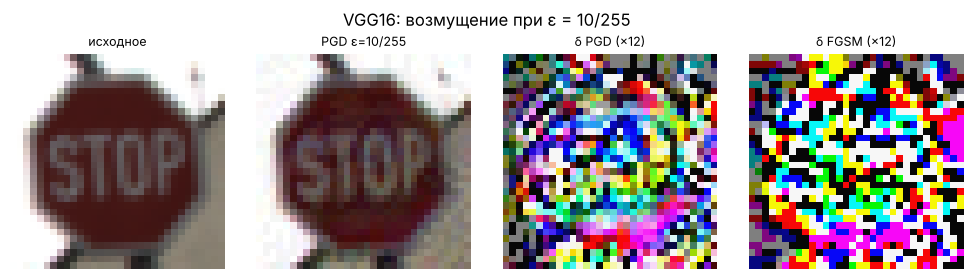

In [26]:
# Как выглядит само возмущение δ = x_adv − x (усилено для наглядности)
name = 'VGG16'
fig, axes = plt.subplots(1, 4, figsize=(10, 2.8))
x0 = x_stop[EX_STOP][0]
for ax, (title, img) in zip(axes, [
        ('исходное', x0),
        ('PGD ε=10/255', stop_examples[(name, 'PGD', 10)][0]),
        ('δ PGD (×12)', np.clip(0.5 + 12 * (stop_examples[(name, 'PGD', 10)][0] - x0), 0, 1)),
        ('δ FGSM (×12)', np.clip(0.5 + 12 * (stop_examples[(name, 'FGSM', 10)][0] - x0), 0, 1))]):
    ax.imshow(img.transpose(1, 2, 0)); ax.set_title(title, fontsize=9); ax.axis('off')
plt.suptitle(f'{name}: возмущение при ε = 10/255'); plt.tight_layout()
plt.savefig(f'{IMG_DIR}/perturbation_{name}.png', dpi=120); plt.show()

## Выводы

### Задание 1. Обучение классификаторов

* Обе предобученные на ImageNet сети за 6 эпох дообучения хорошо решают задачу:
  **VGG16** — 99,94 % на обучении, 97,96 % на валидации, **97,45 % на тесте**;
  **ResNet50** — 99,98 % / 97,00 % / **95,92 %**.
* Лучшие гиперпараметры по validation: для VGG16 — **SGD (momentum 0.9, Nesterov), lr = 1e-2**; для ResNet50 — **Adam, lr = 1e-3**.
  Маленький lr (1e-4) за короткий подбор не успевает перестроить сеть, а у VGG16 Adam с lr = 1e-3 дал худший результат (37 %):
  слишком большой шаг портит предобученные веса.
* Разрыв между обучением и тестом 2–4 п.п. говорит о небольшом переобучении. ResNet50 на картинках 32×32 немного хуже VGG16:
  она рассчитана на 224×224 и уже после первых слоёв сжимает картинку до 8×8. Лучшая эпоха ResNet50 по validation — пятая.

### Задание 2. Нецелевые атаки FGSM и PGD

* Обе модели **крайне уязвимы**: уже при ε = 1/255 (изменение на 1 уровень яркости, глазом не видно) accuracy падает
  с 97–98 % до 66–84 %, при ε = 5/255 — до 10–40 %.
* Требование задания выполнено: при ε = 10/255 accuracy **VGG16: FGSM 23,0 %, PGD 0,5 %; ResNet50: FGSM 26,2 %, PGD 1,6 %**.
* **PGD сильнее FGSM при любом ε.** FGSM делает один шаг по линейному приближению и даже при ε = 80/255 оставляет 4–5 %
  правильных ответов. PGD пересчитывает градиент на каждом из 10 шагов, «следует» за изгибами границы классов и уже
  при ε = 20/255 доводит accuracy до 0–0,1 %. Цена — в 10 раз больше вычислений.
* Обе модели одинаково уязвимы к FGSM. К PGD при малых ε ResNet50 чуть уязвимее (65,7 % против 76,4 % при ε = 1/255).
* Важный методический вывод: с обычной `nn.CrossEntropyLoss` атаки на VGG16 были «замаскированы» (FGSM при ε = 10/255 —
  60,3 %, PGD при ε = 80/255 — 20 %) из-за насыщения softmax у очень уверенной модели. Ложную стойкость устраняет
  `StableCrossEntropy` (раздел 2.0).

### Дополнительно. Перенос атак (чёрный ящик)

* Примеры, построенные на одной модели, обманывают и другую: при ε = 10/255 accuracy жертвы падает до 59–67 %,
  при ε = 20/255 — до 39–42 %, при ε = 80/255 — до 5–8 %. Атака чёрного ящика слабее атаки белого ящика
  (0,5–26 % при ε = 10/255), но работает, не зная весов жертвы.
* PGD и FGSM переносятся почти одинаково: преимущество PGD — тонкая подгонка под конкретную модель, и при переносе она
  в основном теряется.

### Задание 3. Целевая атака «Стоп» → «Ограничение скорости 30»

* **PGD** быстро достигает цели: у VGG16 доля «Огр. 30» — 62,6 % при ε = 3/255, 96,7 % при 5/255 и **100 % начиная с 10/255**;
  у ResNet50 — 75,2 % при 5/255, 93,3 % при 10/255, 99,3 % при 20/255 и 100 % с 50/255.
* **Максимальная производительность** (100 %) достигается при ε = 10/255 для VGG16 и ε = 50/255 для ResNet50 (99,3 % уже при
  20/255). Дальше увеличивать ε бессмысленно: успех не растёт, а шум становится заметнее. Лучший выбор для атакующего —
  наименьшее ε, при котором успех почти 100 %: **10/255 для VGG16 и 20/255 для ResNet50**. Причина: чем больше ε, тем больше
  область, в которой PGD ищет пример. Как только ε-окрестность каждой картинки «дотягивается» до области класса
  «Огр. 30», успех упирается в 100 %. Знаки похожи (красная окантовка, светлый центр), поэтому хватает небольшого ε.
* **FGSM** для целевой атаки почти бесполезен: максимум **17,4 %** (VGG16) и **18,9 %** (ResNet50) при ε = 10/255, а при больших ε
  успех снова падает (у VGG16 до 0 % при ε ≥ 50/255), хотя знак «Стоп» модель перестаёт узнавать. Картинки уходят в
  **другие** классы, чаще всего в «Огр. 50». Один шаг по линейному приближению «перелетает» узкую область целевого класса.
  Чтобы попасть в конкретный класс, нужен итеративный метод.
* **Сравнение:** PGD в целевой атаке на порядок эффективнее FGSM (100 % против ≤ 19 %) ценой примерно в 20 раз большего
  времени (20 итераций). FGSM годится для быстрой нецелевой атаки, PGD — для целевой и для честной оценки стойкости.

### Общий вывод

Классификаторы дорожных знаков с точностью 96–97 % не имеют никакой стойкости к атакам уклонения. Незаметное глазу
изменение пикселей (ε = 10/255) превращает **все** знаки «Стоп» в «Ограничение скорости 30» в режиме белого ящика и заметно
снижает точность даже в режиме чёрного ящика через перенос. Для систем, где ошибка опасна (автопилот), нужны защиты:
состязательное обучение (adversarial training), сертифицированная стойкость, ансамбли разных архитектур. Оценивать
стойкость нужно сильными итеративными атаками и с проверкой на маскировку градиента.